In [1]:
import matplotlib.pyplot as plt
import MDAnalysis as mda
import numpy as np
from scipy.stats import linregress
import pandas as pd
from matplotlib.colors import CenteredNorm, Normalize
from tqdm import tqdm

from mg_sampling import PROJECT_DIR
from mg_sampling.density.align import reorder_residue_atoms
from mg_sampling.density.grid import Grid, SparseGrid
from mg_sampling.density.utils import indices_to_mask, voxels_around
from mg_sampling.tools import edges_to_range, bayesian_bootstrap

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Replex

path = PROJECT_DIR / "density"

data = []
for filename in path.glob("*/all/replicate?_rep??.pkl"):
    weight_file = filename.with_stem(filename.stem + "_weight").with_suffix(".txt")
    if weight_file.exists():
        with open(weight_file, "r") as f:
            weight = float(f.read())
    else:
        weight = 1

    data.append(
        dict(
            sim=filename.parent.parent.name,
            block=filename.stem,
            filename=str(filename),
            map=SparseGrid.load(filename),
            weight=weight,
        )
    )
gen_maps = pd.DataFrame(data)
gen_maps["weight"] /= gen_maps.groupby("sim")["weight"].transform("sum")
gen_map_avg = gen_maps.groupby(['sim'])[['map', 'weight']].apply(lambda x: np.average(x['map'], weights=x['weight']).to_dense())

In [3]:
ref_map = 0.5 * (Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_A.mrc") + Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_B.mrc"))
rna = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb").select_atoms("nucleic and not type H and not (resid 22 and name P OP1 OP2)")

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


In [4]:
cc_mask = indices_to_mask(voxels_around(rna, 6, ref_map.grid_params), ref_map.grid_params)

### Plot CC as a function of B-factor

In [5]:
labeldict = {
    'plain_md_7ez0_mMg_tip3p': "μMg (MD)",
    'plain_md_7ez0_nMg_tip3p': "nMg (MD)",
    'plain_md_7ez0_nMg_tip3p_soft': "nMg (MD-soft)",
    'plain_md_7ez0_noion_nMg_tip3p': "nMg (MD-denovo)",
    'plain_md_7ez0_nomg_mMg_tip3p': "$\emptyset$Mg (MD)",
    'replex_7ez0_mMg_tip3p': "μMg (REx)",
    'replex_7ez0_noion_mMg_tip3p': "μMg (REx-denovo)",
}

In [6]:
tempfactors = np.linspace(0, 100, 20 + 1)

ref_data = ref_map.grid[cc_mask]

def get_cc(map_, tempfactor):
    return linregress(map_.apply_tempfactor(tempfactor).grid[cc_mask], ref_data).rvalue

results = {
    label: [get_cc(map_, tempfactor) for tempfactor in tqdm(tempfactors)]
    for label, map_ in gen_map_avg.items()
}

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:42<00:00,  2.04s/it]


Text(0, 0.5, 'Pearson correlation')

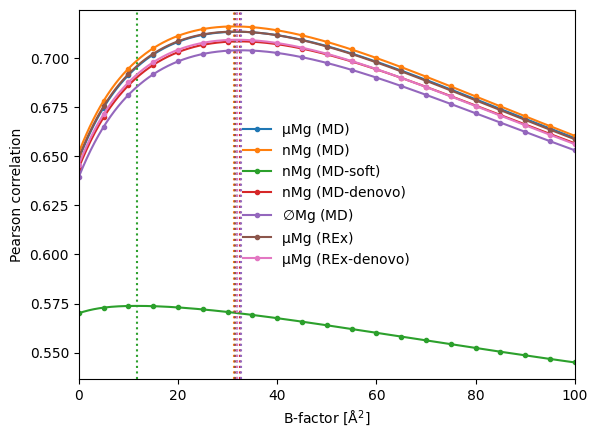

In [7]:
from scipy.interpolate import interp1d
fig, ax = plt.subplots()

tempfactor_range = np.linspace(0, 100, 1001)

best_tempfactor = {}
handles, labels = [], []
for sim, cc in results.items():
    marks, = ax.plot(tempfactors, cc, marker='.', ls='none')
    f = interp1d(tempfactors, cc, kind='cubic')
    cc_interp = f(tempfactor_range)
    line, = ax.plot(tempfactor_range, cc_interp, color=marks.get_color())
    handles.append((marks, line))
    best_tempfactor[sim] = tempfactor_range[np.argmax(cc_interp)]
    ax.axvline(best_tempfactor[sim], color=line.get_color(), ls='dotted')
    labels.append(labeldict[sim])

ax.legend(handles, labels, frameon=False)
ax.set_xlim(0, 100)
ax.set_xlabel("B-factor [Å$^2$]")
ax.set_ylabel("Pearson correlation")

In [10]:
np.mean(list(best_tempfactor.values()))

np.float64(29.071428571428577)